# 10 · Robustness check

This notebook checks how the saved CNN responds to controlled image corruption. It measures accuracy on the clean supplied test images, then on images with increasing Gaussian noise, rotation, or translation. It does not retrain or tune the model.

The supplied test split shares writer IDs with the original training split, as noted in notebooks 01 and 09. Treat these as descriptive stress-test results for this test split, not as a writer-independent benchmark. Do not use the corruption results to select new model settings.


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.robustness import evaluate_condition


## Load the saved model and test data

Use the tuned model produced by notebook 08 and the same EMNIST test split used in the earlier evaluation. Image values are normalized to 0–1 before corruption and prediction.


In [2]:
model = tf.keras.models.load_model("../models/cnn_writer_independent.keras")
_, _, writers_train, X_test, y_test, writers_test = load_emnist()
X_test = preprocess_images(X_test)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Writer IDs shared with original training split:",
      len(set(writers_train) & set(writers_test)))


W0000 00:00:1790189370.003517   64580 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Test images: (40000, 28, 28, 1)
Test labels: (40000,)
Writer IDs shared with original training split: 3577


## Define controlled corruption levels

Rotation and translation use Keras image layers with fixed random seeds, so each severity is reproducible when the notebook is run from the beginning. Noise is additive Gaussian noise on the normalized image range. Pixel values are clipped to 0–1 after noise is added.

The rotation levels are maximum random rotations of ±3°, ±6°, and ±10°. Translation levels are maximum random shifts of ±1, ±2, and ±3 pixels in each direction. Noise levels are standard deviations of 0.05, 0.10, and 0.20.


In [3]:
BATCH_SIZE = 512
rotation_degrees = [3, 6, 10]
translation_pixels = [1, 2, 3]
noise_sigmas = [0.05, 0.10, 0.20]

corruptions = {"clean": None}
for level, degrees in enumerate(rotation_degrees, start=1):
    corruptions[f"rotation_{degrees}deg"] = tf.keras.layers.RandomRotation(
        factor=degrees / 360.0,
        fill_mode="constant",
        fill_value=0.0,
        seed=100 + level,
    )
for level, pixels in enumerate(translation_pixels, start=1):
    fraction = pixels / 28.0
    corruptions[f"translation_{pixels}px"] = tf.keras.layers.RandomTranslation(
        height_factor=fraction,
        width_factor=fraction,
        fill_mode="constant",
        fill_value=0.0,
        seed=200 + level,
    )
for level, sigma in enumerate(noise_sigmas, start=1):
    corruptions[f"noise_{sigma:.2f}"] = ("noise", sigma, 300 + level)


## Evaluate clean and corrupted images

The shared `evaluate_condition` function in `src/robustness.py` processes images in batches to limit memory use. The same labels are used for every transformed image. Accuracy and loss are descriptive measurements only; this notebook does not fit or select model settings.


In [ ]:
results = {}
for name, condition in corruptions.items():
    print(f"Evaluating {name}...")
    seed = condition[2] if isinstance(condition, tuple) and condition[0] == "noise" else 0
    results[name] = evaluate_condition(
        model, X_test, y_test, condition, batch_size=BATCH_SIZE, seed=seed
    )
    print(f"  accuracy={results[name]['accuracy']:.4f}, "
          f"loss={results[name]['loss']:.4f}")


## Compare accuracy as corruption increases

Each line starts from clean accuracy and then shows the result at the three severities for that corruption type. A steeper decline means the model is more sensitive to that kind of change over the tested range.


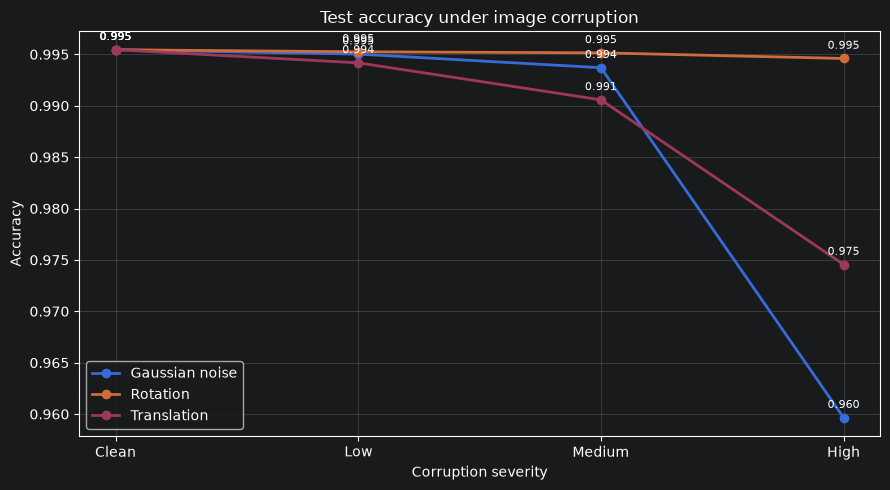

In [13]:
severity_labels = ["Clean", "Low", "Medium", "High"]
series = {
    "Gaussian noise": ["clean", "noise_0.05", "noise_0.10", "noise_0.20"],
    "Rotation": ["clean", "rotation_3deg", "rotation_6deg", "rotation_10deg"],
    "Translation": ["clean", "translation_1px", "translation_2px", "translation_3px"],
}

plt.figure(figsize=(9, 5))
for label, keys in series.items():
    accuracies = [results[key]["accuracy"] for key in keys]
    plt.plot(severity_labels, accuracies, marker="o", linewidth=2, label=label)
    for x, value in enumerate(accuracies):
        plt.annotate(f"{value:.3f}", (x, value), textcoords="offset points",
                     xytext=(0, 7), ha="center", fontsize=8)
plt.ylabel("Accuracy")
plt.xlabel("Corruption severity")
plt.title("Test accuracy under image corruption")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Compare accuracy and loss changes

This table reports the accuracy drop and loss increase from the clean condition to the high-severity condition. Larger changes indicate greater sensitivity within the tested range. These results describe the saved model; they are not a reason to tune against this test set.


In [7]:
summary_rows = []
for corruption, keys in series.items():
    clean = results[keys[0]]
    high = results[keys[-1]]
    summary_rows.append({
        "corruption": corruption,
        "clean_accuracy": clean["accuracy"],
        "high_severity_accuracy": high["accuracy"],
        "accuracy_drop_percentage_points": 100 * (clean["accuracy"] - high["accuracy"]),
        "clean_loss": clean["loss"],
        "high_severity_loss": high["loss"],
        "loss_increase": high["loss"] - clean["loss"],
    })
summary_table = pd.DataFrame(summary_rows).sort_values(
    "accuracy_drop_percentage_points", ascending=False
)
print(summary_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


    corruption  clean_accuracy  high_severity_accuracy  accuracy_drop_percentage_points  clean_loss  high_severity_loss  loss_increase
Gaussian noise          0.9954                  0.9597                           3.5800      0.0157              0.1298         0.1141
   Translation          0.9954                  0.9746                           2.0900      0.0157              0.0902         0.0745
      Rotation          0.9954                  0.9946                           0.0850      0.0157              0.0185         0.0028


## View examples of the highest-severity transformations

These panels show the same sample images before and after the strongest tested noise, rotation, and translation. Since rotation and translation are randomized within their ranges, these examples illustrate plausible transformations rather than a single fixed offset or angle.


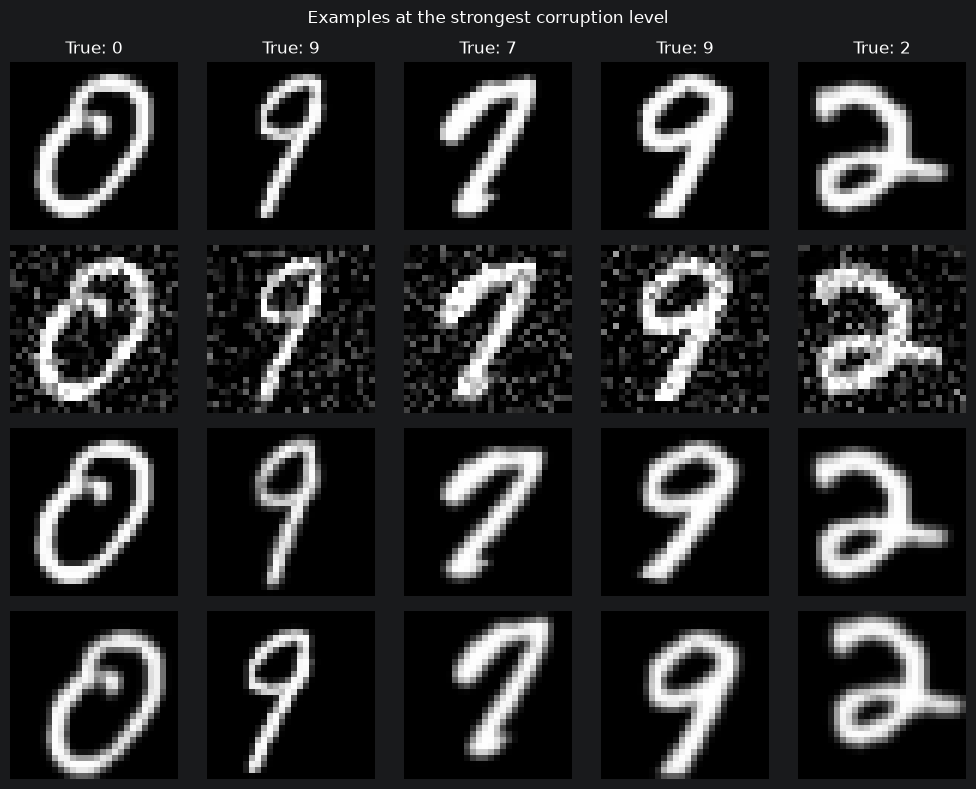

In [8]:
sample_images = tf.convert_to_tensor(X_test[:5], dtype=tf.float32)
example_transformations = [
    ("Clean", None),
    ("Noise σ=0.20", corruptions["noise_0.20"]),
    ("Rotation ±10°", corruptions["rotation_10deg"]),
    ("Translation ±3px", corruptions["translation_3px"]),
]

fig, axes = plt.subplots(len(example_transformations), len(sample_images), figsize=(10, 8))
for row, (title, transformation) in enumerate(example_transformations):
    if transformation is None:
        shown = sample_images.numpy()
    elif isinstance(transformation, tuple):
        _, sigma, seed = transformation
        rng = np.random.default_rng(seed)
        noise = rng.normal(0.0, sigma, size=sample_images.shape).astype(np.float32)
        shown = tf.clip_by_value(sample_images + noise, 0.0, 1.0).numpy()
    else:
        shown = transformation(sample_images, training=True).numpy()
    for col, ax in enumerate(axes[row]):
        ax.imshow(shown[col].squeeze(), cmap="gray", vmin=0, vmax=1)
        if row == 0:
            ax.set_title(f"True: {int(y_test[col])}")
        if col == 0:
            ax.set_ylabel(title)
        ax.axis("off")
fig.suptitle("Examples at the strongest corruption level")
plt.tight_layout()
plt.show()


## Save the measurements

Save all clean and corrupted accuracy/loss measurements to a new results file for reference. The file is descriptive only and does not affect model selection.


In [9]:
output = {
    "model": "cnn_writer_independent.keras",
    "test_split_note": "Supplied test writers overlap with original training writers; stress test is descriptive.",
    "corruptions": {
        name: {
            "accuracy": float(values["accuracy"]),
            "loss": float(values["loss"]),
            "correct": int(values["correct"]),
            "total": int(values["total"]),
        }
        for name, values in results.items()
    },
    "high_severity_summary": summary_rows,
}
with open("../models/robustness_results.json", "w") as f:
    json.dump(output, f, indent=2)
    f.write("\n")
print("Saved results to ../models/robustness_results.json")


Saved results to ../models/robustness_results.json


## Results and interpretation

In the saved run, clean test accuracy was **99.54%**. At the highest tested severity, Gaussian noise reduced accuracy to **95.97%** (a **3.58 percentage-point** drop), translation reduced it to **97.46%** (a **2.09-point** drop), and rotation reduced it to **99.46%** (a **0.085-point** drop). Noise had the largest effect in this range, followed by translation; the model was least affected by rotation.

These measurements use the supplied test split, whose writer IDs overlap with the original training split. They are descriptive stress-test results, not writer-independent performance estimates, and should not be used to tune the model.
